<a href="https://colab.research.google.com/github/wkwkwwk0712-debug/kkyu-repo/blob/fix%2Flyria-api/PMCO_Colab_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PMCO | Colab v2 (가중치 실험용)

원래 제공한 PMCO 스타터 노트북을 바탕으로 만든 **별도 버전**입니다. 사용자가 Colab에서 직접 추가 수정한 최신 노트북과 동일하지 않을 수 있습니다. 기존 노트북을 덮어쓰지 마세요.

- 최초 가중치 **0.40 / 0.35 / 0.25** 그대로 유지
- 실험 프로필 **complexity_experiment**, **contrast_experiment** 추가
- ⑨ CSV 누적 저장 보호 및 다른 프로필 기록 지원
- 별도 비교 CSV 생성으로 가중치 변경 전후 출력 비교
- **사람 평가 점수가 비어 있으므로 성능 개선이 검증된 것은 아닙니다.**

Colab에서는 ① 설치 → ② 모듈 생성 → ③ 사진 업로드 → ④ 특징 계산 → ⑤ 매핑 → ⑨ 저장을 실행합니다.


## ① 준비 — Colab에서 셀 실행
왼쪽 ▶ 버튼 또는 Shift+Enter. 첫 셀을 실행해 라이브러리를 설치합니다.

In [1]:
!pip -q install -U numpy pillow pandas matplotlib requests beautifulsoup4 google-genai

## ② 매핑 알고리즘 파일 만들기 (v2)
다음 셀을 실행하면 `pmco_core_v2.py`를 만듭니다. 새 런타임에서 반드시 다시 실행하세요. 기존 `pmco_core.py`는 덮어쓰지 않습니다.

In [2]:
%%writefile pmco_core_v2.py
"""PMCO: interpretable prototype image-feature to music-parameter mapping.

These heuristics are design hypotheses, NOT scientifically validated perceptual laws.
"""
from __future__ import annotations
from dataclasses import dataclass, asdict
from io import BytesIO
from typing import Optional
import numpy as np
from PIL import Image

@dataclass
class ImageFeatures:
    brightness: float
    saturation: float
    contrast: float
    complexity: float
    warmth: float

@dataclass
class MusicPlan:
    energy: float
    valence: float
    bpm: int
    genre: str
    instrument: str
    dynamics: str
    explanation: dict

def _clip01(n):
    return float(np.clip(n, 0.0, 1.0))

def extract_features(image: Image.Image | bytes) -> ImageFeatures:
    """Return five [0,1] proxies. 'complexity' is local edge magnitude, not scene motion."""
    if isinstance(image, bytes):
        image = Image.open(BytesIO(image))
    image = image.convert('RGB')
    image.thumbnail((512, 512))
    rgb = np.asarray(image, dtype=np.float32) / 255.0
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    y = 0.2126 * r + 0.7152 * g + 0.0722 * b
    sat = np.asarray(image.convert('HSV'), dtype=np.float32)[..., 1] / 255.0
    diff_h = np.abs(np.diff(y, axis=1)).mean() if y.shape[1] > 1 else 0.0
    diff_v = np.abs(np.diff(y, axis=0)).mean() if y.shape[0] > 1 else 0.0
    # Approximate scaling is a project hypothesis; adjust using labeled data.
    return ImageFeatures(
        brightness=_clip01(y.mean()),
        saturation=_clip01(sat.mean()),
        contrast=_clip01(y.std() / 0.35),
        complexity=_clip01((diff_h + diff_v) / 0.28),
        warmth=_clip01(0.5 + float((r - b).mean()) * 0.9),
    )

def map_music(features: ImageFeatures, energy_override: Optional[float]=None,
              weights: tuple[float,float,float]=(0.40, 0.35, 0.25)) -> MusicPlan:
    """Transparent deterministic mapping: complexity, saturation, contrast -> energy."""
    w = np.asarray(weights, dtype=float)
    if not np.isfinite(w).all() or (w < 0).any() or w.sum() <= 0:
        raise ValueError('weights must be nonnegative and sum to a positive value')
    w /= w.sum()
    contributions = {
        'complexity': float(w[0] * features.complexity),
        'saturation': float(w[1] * features.saturation),
        'contrast': float(w[2] * features.contrast),
    }
    raw = sum(contributions.values())
    energy = _clip01(raw if energy_override is None else energy_override)
    valence = _clip01(0.45 * features.brightness + 0.35 * features.warmth + 0.20 * features.saturation)
    bpm = round(55 + 95 * energy)
    if energy < 0.33:
        genre, dynamics = 'ambient / minimalist', 'soft, slow development'
        instrument = 'warm piano, airy pads' if features.warmth > 0.5 else 'felt piano, soft strings'
    elif energy < 0.67:
        genre, dynamics = 'acoustic / cinematic', 'gentle pulse, moderate intensity'
        instrument = 'acoustic guitar, strings' if features.warmth > 0.5 else 'piano, light percussion'
    else:
        genre, dynamics = 'cinematic / energetic', 'rhythmic, lively accents'
        instrument = 'bright percussion, plucked strings' if features.warmth > 0.5 else 'synths, drums'
    return MusicPlan(energy=energy, valence=valence, bpm=bpm, genre=genre,
                     instrument=instrument, dynamics=dynamics, explanation={
                         'weight_complexity': round(float(w[0]), 3),
                         'weight_saturation': round(float(w[1]), 3),
                         'weight_contrast': round(float(w[2]), 3),
                         'weighted_complexity': round(contributions['complexity'], 4),
                         'weighted_saturation': round(contributions['saturation'], 4),
                         'weighted_contrast': round(contributions['contrast'], 4),
                         'computed_energy_before_override': round(raw, 4),
                         'energy_overridden': energy_override is not None,
                     })

def build_music_prompt(plan: MusicPlan, scene_description: str='') -> str:
    scene = scene_description.strip().replace('\n', ' ')[:500]
    return (
        'Create an original instrumental music clip. No vocals, no lyrics, '
        'no imitation of copyrighted recordings or named artists. '
        f'Target tempo approximately {plan.bpm} BPM. '
        f'Energy {plan.energy:.2f}/1, emotional brightness {plan.valence:.2f}/1. '
        f'Style: {plan.genre}. Instruments: {plan.instrument}. '
        f'Dynamics: {plan.dynamics}. '
        'Express the visual atmosphere with musical texture, not literal sounds. '
        + (f'Image scene notes: {scene}.' if scene else '')
    )

def plan_record(filename: str, features: ImageFeatures, plan: MusicPlan) -> dict:
    base={'filename':filename, **asdict(features)}
    for k,v in asdict(plan).items():
        if k != 'explanation': base[k] = v
    for k,v in plan.explanation.items(): base[k] = v
    return base


# Two explicit experiment profiles; neither is validated as "better" without human labels.
WEIGHT_PROFILES = {
    "baseline": (0.40, 0.35, 0.25),
    "complexity_experiment": (0.50, 0.20, 0.30),
    "contrast_experiment": (0.35, 0.25, 0.40),
}

def map_music_profile(features: ImageFeatures, profile: str = "baseline",
                      energy_override: Optional[float] = None) -> MusicPlan:
    """Use an explicitly selected experiment profile; baseline is unchanged."""
    if profile not in WEIGHT_PROFILES:
        raise ValueError(f"Unknown profile {profile!r}; choose {list(WEIGHT_PROFILES)}")
    return map_music(features, energy_override=energy_override,
                     weights=WEIGHT_PROFILES[profile])


Overwriting pmco_core_v2.py


## ③ 개인 사진 업로드
공개 가능한 사진만 사용하세요. 고요한 풍경, 활기찬 시장 등 분위기가 다른 사진 두 장을 비교하면 좋습니다.

Saving 램파드.jpg to 램파드.jpg


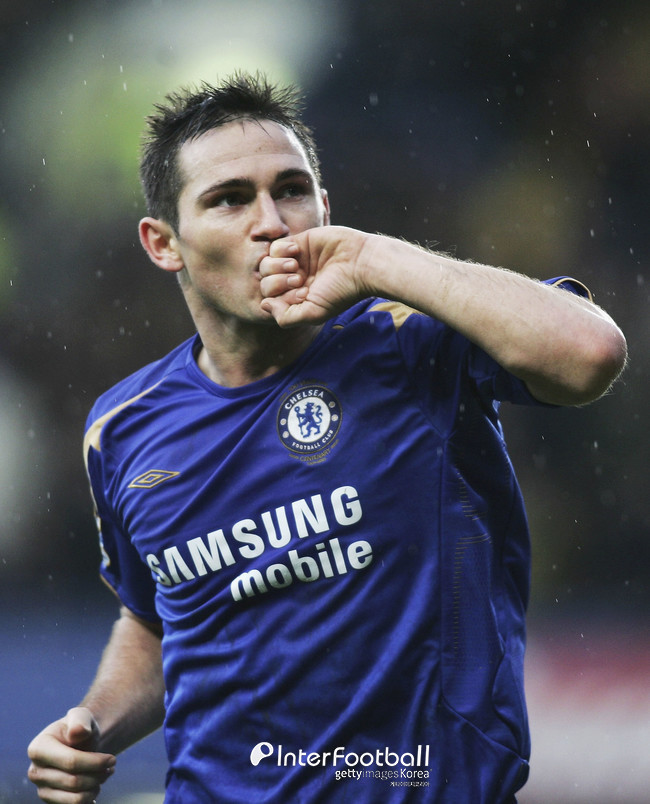

In [3]:
from google.colab import files
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
from pmco_core_v2 import extract_features, map_music_profile, build_music_prompt, plan_record, WEIGHT_PROFILES
uploaded=files.upload()
if not uploaded: raise ValueError('사진 파일 한 장을 업로드해 줘.')
filename, image_bytes=next(iter(uploaded.items()))
photo=Image.open(BytesIO(image_bytes)).convert('RGB')
display(photo.resize((min(photo.width,700), int(photo.height*min(photo.width,700)/photo.width))))

## ④ 시각 특징 5종 계산
- 밝기/채도/대비/경계 복잡도/붉은색-푸른색 상대 비율(색온감의 간단한 대리지표)
- **움직임** 자체를 인식하지 않는다는 점에 주의!

In [4]:
import pandas as pd
features=extract_features(photo)
display(pd.DataFrame([vars(features)]).T.rename(columns={0:'normalized_value'}))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


,normalized_value
brightness,0.308819
saturation,0.291009
contrast,0.608240
complexity,0.138797
warmth,0.441910


## ⑤ 음악 매핑 — 검증 전인 가중치 실험 프로필
`WEIGHT_PROFILE='baseline'`으로 기존 결과를 재현할 수 있습니다. 테스트 목적일 때만 다른 프로필로 변경하세요. `genre`/`bpm`도 에너지에 따라 바뀔 수 있습니다.

In [5]:
WEIGHT_PROFILE = "baseline"  # "complexity_experiment" 또는 "contrast_experiment"
music = map_music_profile(features, profile=WEIGHT_PROFILE)
print('프로필:', WEIGHT_PROFILE, '| 가중치:', WEIGHT_PROFILES[WEIGHT_PROFILE])
print('BPM:', music.bpm, '| Energy:', round(music.energy, 4))
print('Genre:', music.genre, '| Instruments:', music.instrument)
print('각 특징의 기여도:', music.explanation)
prompt = build_music_prompt(music)
print('\n음악 생성 프롬프트:\n', prompt)

프로필: baseline | 가중치: (0.4, 0.35, 0.25)
BPM: 84 | Energy: 0.3094
Genre: ambient / minimalist | Instruments: felt piano, soft strings
각 특징의 기여도: {'weight_complexity': 0.4, 'weight_saturation': 0.35, 'weight_contrast': 0.25, 'weighted_complexity': 0.0555, 'weighted_saturation': 0.1019, 'weighted_contrast': 0.1521, 'computed_energy_before_override': 0.3094, 'energy_overridden': False}

음악 생성 프롬프트:
 Create an original instrumental music clip. No vocals, no lyrics, no imitation of copyrighted recordings or named artists. Target tempo approximately 84 BPM. Energy 0.31/1, emotional brightness 0.35/1. Style: ambient / minimalist. Instruments: felt piano, soft strings. Dynamics: soft, slow development. Express the visual atmosphere with musical texture, not literal sounds. 


## ⑥ 사용자 개입 실험: 같은 사진으로 에너지만 변경
출력이 바뀌는지 확인하고 나중에 A/B 비교 시 이용합니다.

In [6]:
from pmco_core_v2 import map_music
cases=[map_music(features,energy_override=x) for x in [0.20,0.50,0.85]]
display(pd.DataFrame([{'energy_override':x,'BPM':p.bpm,'genre':p.genre,'instrument':p.instrument} for x,p in zip([0.20,0.50,0.85],cases)]))

,energy_override,BPM,genre,instrument
0,0.20,74,ambient / minimalist,"felt piano, soft strings"
1,0.50,102,acoustic / cinematic,"piano, light percussion"
2,0.85,136,cinematic / energetic,"synths, drums"


## ⑦ (선택) Gemini에게 사진 분위기 설명받기 — 유료 호출 가능
왼쪽 열쇠(Secrets)에 `GEMINI_API_KEY`를 저장하고 노트북 접근을 허용하세요. **키 문자열을 이 노트북에 직접 입력하지 마세요.**
처음에는 `USE_GEMINI = False`로 실행하세요.

In [7]:
USE_GEMINI = False  # 사용자가 True로 변경해야 실제 유료 API 호출
scene_description = ''
if USE_GEMINI:
    from google.colab import userdata
    from google import genai
    from google.genai import types
    client=genai.Client(api_key=userdata.get('GEMINI_APIKEY'))
    from mimetypes import guess_type
    mime=guess_type(filename)[0] or 'image/jpeg'
    response=client.models.generate_content(
        model='gemini-3.8-flash',
        contents=[types.Part.from_bytes(data=image_bytes,mime_type=mime),
                  '사진에서 관찰 가능한 장면과 고요함/역동성, 계절, 분위기를 한국어로 2문장 설명해줘. 불확실한 내용은 추정이라고 표현해.'],
    )
    scene_description=response.text or ''
    print(scene_description)
else:
    print('Gemini 호출 생략: 비용 없이 수치 알고리즘을 테스트합니다.')
prompt=build_music_prompt(music,scene_description)
print('\n최종 프롬프트:\n',prompt)

Gemini 호출 생략: 비용 없이 수치 알고리즘을 테스트합니다.

최종 프롬프트:
 Create an original instrumental music clip. No vocals, no lyrics, no imitation of copyrighted recordings or named artists. Target tempo approximately 84 BPM. Energy 0.31/1, emotional brightness 0.35/1. Style: ambient / minimalist. Instruments: felt piano, soft strings. Dynamics: soft, slow development. Express the visual atmosphere with musical texture, not literal sounds. 


In [8]:
# ⑦ Gemini 결과와 음악 매핑 결과 연결
from pmco_core_v2 import (
    map_music_profile,
    build_music_prompt
)

music = map_music_profile(
    features,
    profile="baseline"
)

prompt = build_music_prompt(
    music,
    scene_description
)

print("최종 음악 생성 프롬프트:")
print(prompt)

최종 음악 생성 프롬프트:
Create an original instrumental music clip. No vocals, no lyrics, no imitation of copyrighted recordings or named artists. Target tempo approximately 84 BPM. Energy 0.31/1, emotional brightness 0.35/1. Style: ambient / minimalist. Instruments: felt piano, soft strings. Dynamics: soft, slow development. Express the visual atmosphere with musical texture, not literal sounds. 


## ⑧ Lyria 3으로 실제 MP3 만들기 — 유료 호출
모델- lyria-3-clip-preview

**호출하려는 경우** `GENERATE_PAID_MUSIC = True`

In [9]:
# ==================================================
# ⑧ Lyria 음악 생성 - v1beta API 수정본
# ==================================================

GENERATE_PAID_MUSIC = True
OUTPUT_FILE = "M01_P03.mp3"

if GENERATE_PAID_MUSIC:

    import base64
    from google import genai
    from google.genai import types
    from google.colab import userdata, files
    from IPython.display import Audio, display

    # 1. 기존 음악 프롬프트 확인
    if "prompt" not in globals() or not prompt:
        raise RuntimeError(
            "음악 프롬프트가 없습니다. "
            "⑤~⑦번 셀을 먼저 실행하세요."
        )

    # 2. API 키 확인
    api_key = userdata.get("GEMINI_APIKEY")

    if not api_key:
        raise RuntimeError(
            "Colab Secrets에 GEMINI_API_KEY가 없습니다."
        )

    # 3. v1beta API 버전 명시
    client = genai.Client(
        api_key=api_key,
        http_options=types.HttpOptions(
            api_version="v1beta"
        )
    )

    # 4. 음악 생성 요청 (유료)
    print("Lyria 3 음악 생성 요청 중...")

    interaction = client.interactions.create(
        model="lyria-3-clip-preview",
        input=prompt,
        api_version="v1beta"
    )

    # 5. 오디오 데이터 확인
    audio = interaction.output_audio

    if audio is None or not audio.data:
        raise RuntimeError(
            "오디오 데이터가 반환되지 않았습니다."
        )

    # 6. MP3 데이터 변환
    audio_bytes = base64.b64decode(audio.data)

    # 7. 파일 저장
    with open(OUTPUT_FILE, "wb") as f:
        f.write(audio_bytes)

    print("\n음악 생성 완료!")
    print("파일명:", OUTPUT_FILE)
    print("파일 크기:", len(audio_bytes), "bytes")

    # 8. 음악 재생
    display(Audio(filename=OUTPUT_FILE))

    # 9. 파일 다운로드
    files.download(OUTPUT_FILE)

else:
    print("유료 음악 생성이 비활성화되어 있습니다.")

Lyria 3 음악 생성 요청 중...

음악 생성 완료!
파일명: M01_P03.mp3
파일 크기: 746250 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ⑨ KNIME용 누적 CSV 저장 (v2)
동일 파일명·동일 가중치 프로필의 행만 갱신합니다. **기존 파일과 데이터를 잃지 않도록, 다른 Colab 세션에서는 기존 `pmco_evaluation.csv`를 먼저 업로드해야 합니다.** CSV는 PMCO 출력 기록이며 음악 품질의 검증 결과가 아닙니다.

In [ ]:
from pathlib import Path
from pmco_core_v2 import plan_record
import pandas as pd

path = Path("pmco_evaluation.csv")
row = plan_record(filename, features, music)
row.update({
    "prompt": prompt,
    "weight_profile": WEIGHT_PROFILE,
    "human_energy_1to5": pd.NA,
    "human_calmness_1to5": pd.NA,
    "human_music_fit_1to5": pd.NA,
    "notes": "",
})
new_row = pd.DataFrame([row])

if path.exists():
    old = pd.read_csv(path)
    # Uploaded baseline dataset collected before weight_profile column existed.
    if "weight_profile" not in old.columns:
        old["weight_profile"] = "baseline"
    else:
        old["weight_profile"] = old["weight_profile"].fillna("baseline")
    # Preserve existing human evaluations for the same photo/profile if any.
    matching = old.loc[
        (old["filename"] == filename) & (old["weight_profile"] == WEIGHT_PROFILE)
    ]
    if not matching.empty:
        for column in ["human_energy_1to5", "human_calmness_1to5", "human_music_fit_1to5", "notes"]:
            if column in matching.columns:
                existing_value = matching.iloc[-1][column]
                if pd.notna(existing_value):
                    new_row[column] = existing_value
    result = pd.concat([old, new_row], ignore_index=True)
    result = result.drop_duplicates(subset=["filename", "weight_profile"], keep="last")
else:
    result = new_row

result.to_csv(path, index=False, encoding="utf-8-sig")
print("CSV 저장 완료:", path.resolve(), "| 데이터 행:", len(result))
display(result.tail(10))

## ⑨-A 기존 6장 CSV 가중치 민감도 비교
이 분석은 이미 저장된 `pmco_evaluation.csv`로 수행하므로 Gemini/Lyria 호출이나 사진 재업로드가 필요 없습니다. 처음 만든 CSV는 덮어쓰지 않고 별도 `pmco_weight_comparison.csv`를 저장합니다. **상관관계는 모델 성능 검증이 아니고, 사람 평가 점수가 필요합니다.**

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

original = Path('pmco_evaluation.csv')
if not original.exists():
    raise FileNotFoundError('pmco_evaluation.csv를 Colab 파일 창으로 업로드한 다음 실행하세요.')
d = pd.read_csv(original)
required = ['filename','complexity','saturation','contrast','energy']
if not set(required).issubset(d.columns):
    raise ValueError(f'필수 열이 없습니다: {set(required)-set(d.columns)}')

profiles = {
    'baseline': (0.40, 0.35, 0.25),
    'complexity_experiment': (0.50, 0.20, 0.30),
    'contrast_experiment': (0.35, 0.25, 0.40),
}
# Only compare records from baseline, not a mix of different profile rows.
if 'weight_profile' in d.columns:
    d = d[d['weight_profile'].fillna('baseline') == 'baseline'].copy()

v = d[['complexity','saturation','contrast']].to_numpy()
comparison = d[['filename']].copy()
for profile, weights in profiles.items():
    energy = v @ np.array(weights)
    comparison[f'{profile}_energy'] = energy
    comparison[f'{profile}_bpm'] = np.rint(55 + 95 * energy).astype(int)
    comparison[f'{profile}_genre'] = np.select(
        [energy < .33, energy < .67],
        ['ambient / minimalist','acoustic / cinematic'],
        default='cinematic / energetic'
    )
comparison['complexity_delta'] = comparison['complexity_experiment_energy'] - comparison['baseline_energy']
comparison['contrast_delta'] = comparison['contrast_experiment_energy'] - comparison['baseline_energy']
comparison.to_csv('pmco_weight_comparison.csv', index=False, encoding='utf-8-sig')
print('프로필 비교용 CSV 생성 완료. 원본 CSV는 변경되지 않았습니다.')
display(comparison.round(4))

## ⑩ 공식 API로 크롤링 실습: Commons 이미지 *메타데이터*
수업의 Requests/BeautifulSoup을 라이선스 메타데이터 수집에 응용합니다. 실제 다운로드와 공개 사용은 각 이미지 라이선스 확인 후 진행하세요.

In [ ]:
import requests
from bs4 import BeautifulSoup
params={'action':'query','format':'json','generator':'categorymembers','gcmtitle':'Category:Landscapes',
        'gcmtype':'file','gcmlimit':10,'prop':'imageinfo','iiprop':'url|extmetadata','iiurlwidth':640}
try:
    response=requests.get('https://commons.wikimedia.org/w/api.php',params=params,
        headers={'User-Agent':'PMCO-Classroom/0.1 (educational metadata research)'},timeout=30)
    response.raise_for_status()
    data=response.json()
    records=[]
    for page in data.get('query',{}).get('pages',{}).values():
        info=(page.get('imageinfo') or [{}])[0]
        meta=info.get('extmetadata') or {}
        artist=BeautifulSoup((meta.get('Artist') or {}).get('value',''),'html.parser').get_text(' ',strip=True)
        records.append({'file':page.get('title'),'url':info.get('thumburl'),
                        'page':info.get('descriptionurl'),'artist':artist,
                        'license':(meta.get('LicenseShortName') or {}).get('value','')})
    commons_df=pd.DataFrame(records)
    display(commons_df.head())
    commons_df.to_csv('commons_metadata.csv',index=False,encoding='utf-8-sig')
except Exception as exc:
    print('Commons API 네트워크/권한 오류:',type(exc).__name__,str(exc)[:250])
    print('크롤링은 선택 실습이므로 이미지 매핑과 API 부분은 계속 사용할 수 있습니다.')

## ⑪ GitHub 저장 (루브릭: 주기적 커밋·브랜치)
1. 노트북 이름을 `PMCO_Colab_v2.ipynb`로 바꿉니다.
2. **API 키·키 값이 노출된 셀 출력이 없는지 확인**하고, 파일 메뉴에서 `GitHub에 사본 저장`을 선택합니다.
3. 기존 저장소 `wkwkwwk0712-debug/kkyu-repo` 또는 새 PMCO 저장소를 선택하세요.
4. 커밋 메시지 `Add interpretable image-to-music mapping notebook`으로 저장합니다.
5. GitHub에서 `README.md`, 이후 `feature/crawling` 브랜치와 PR을 추가해 개발 이력을 남깁니다.
6. Colab에서 다운로드한 CSV를 KNIME으로 열어 기술 및 평가 결과를 분석합니다.

수업에서 이미 배운 `Git add → commit → push`, `branch → merge`와 연결할 수 있습니다.